# PV dominance
Figures 7–10 and 12. Settings: `dominance.json`. Uses the validated fresh surface-PV product; no rebuild.

Final PNGs: `../figures/`. Tables, reports and manifests: `outputs/`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import Markdown, display

HERE = Path.cwd().resolve()
if (HERE / "pv_dominance" / "dominance.py").is_file():
    HERE = HERE / "pv_dominance"
elif not (HERE / "dominance.py").is_file():
    HERE = HERE / "seacofs_eddy_tilt_analysis" / "manuscript" / "pv_dominance"
sys.path.insert(0,str(HERE))
import dominance
CONFIG = HERE / "dominance.json"

In [2]:
results = dominance.run(CONFIG)
import matplotlib.pyplot as plt
plt.close("all")

pv_gradient_rose


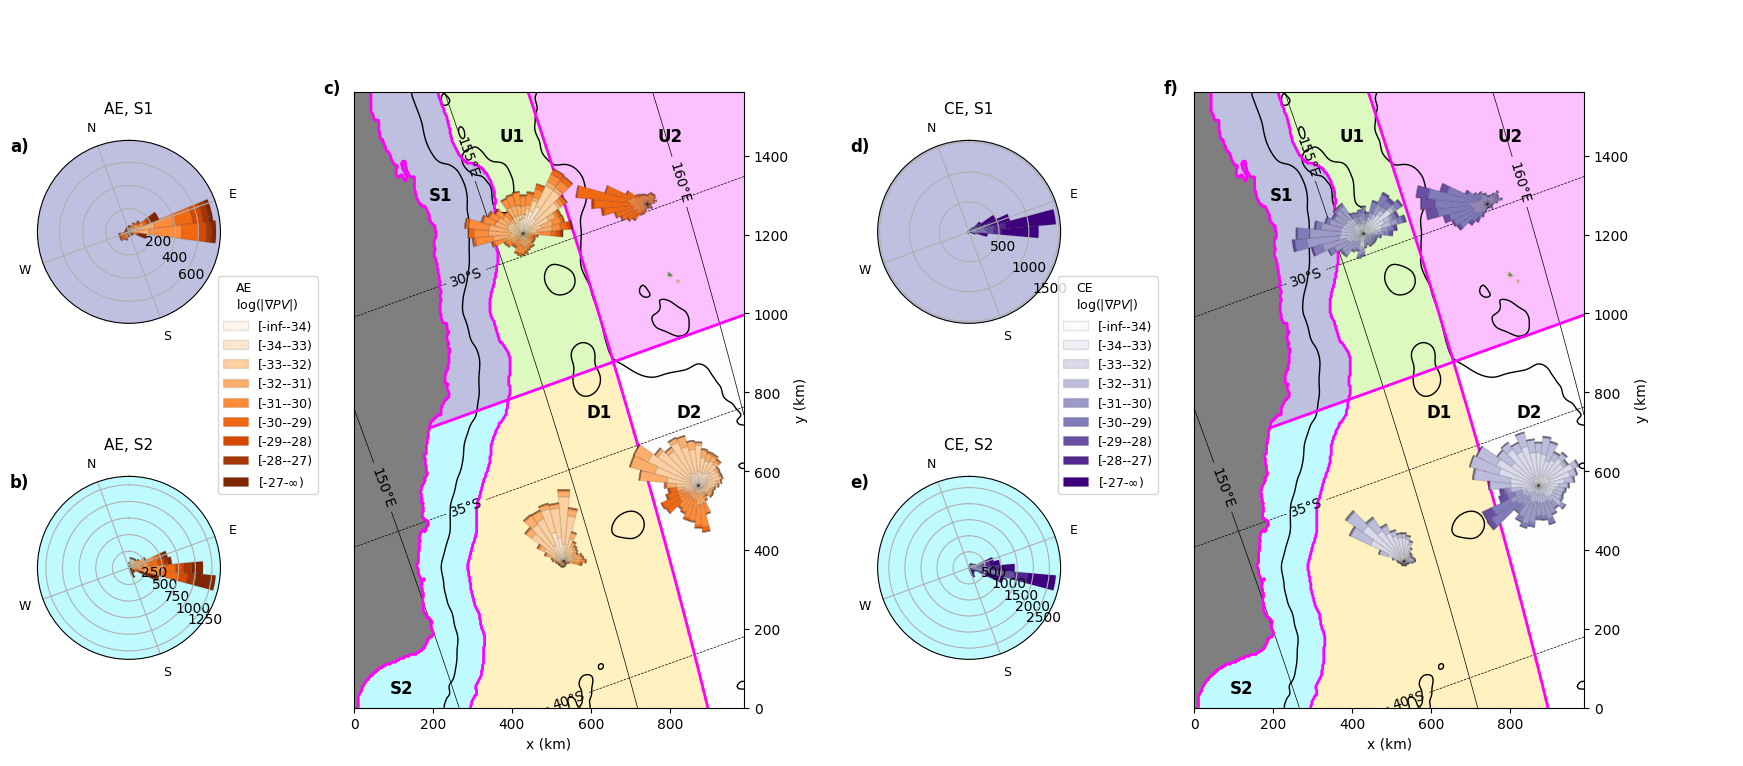

beta_dom_map


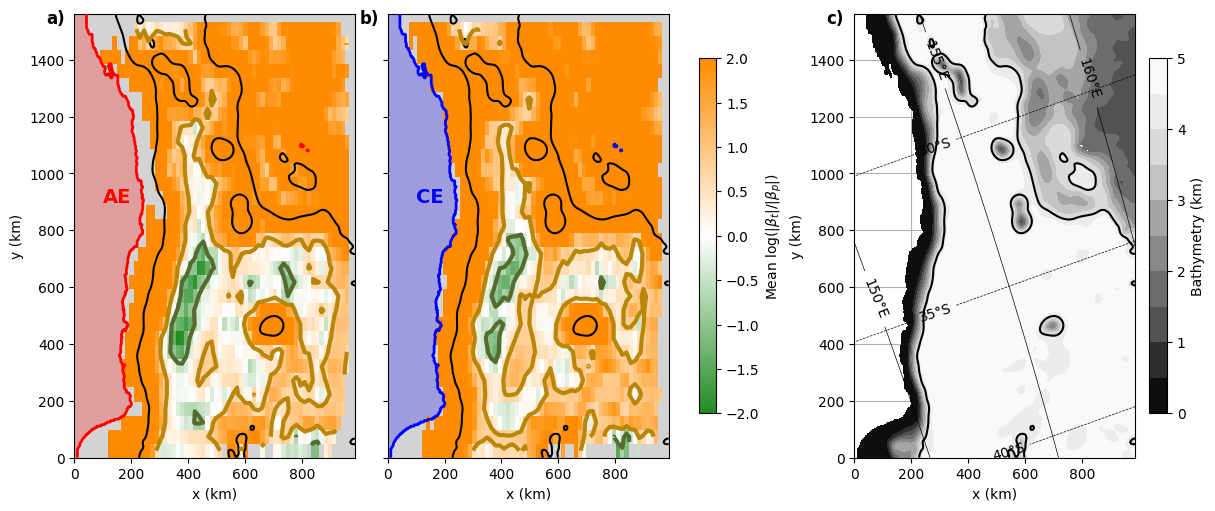

topo_plan_ratio


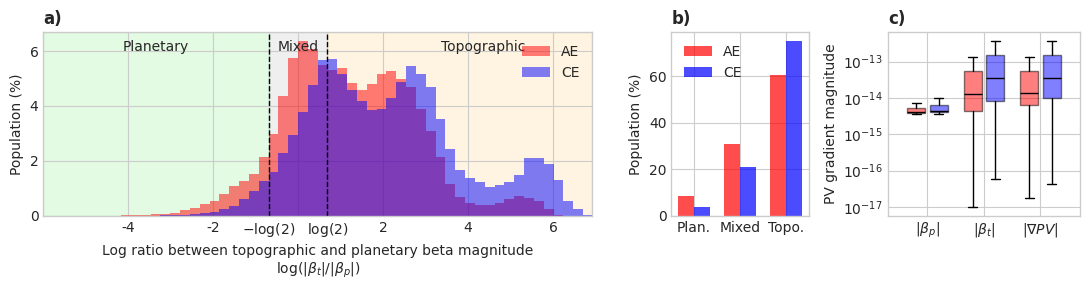

plan_dom_rose


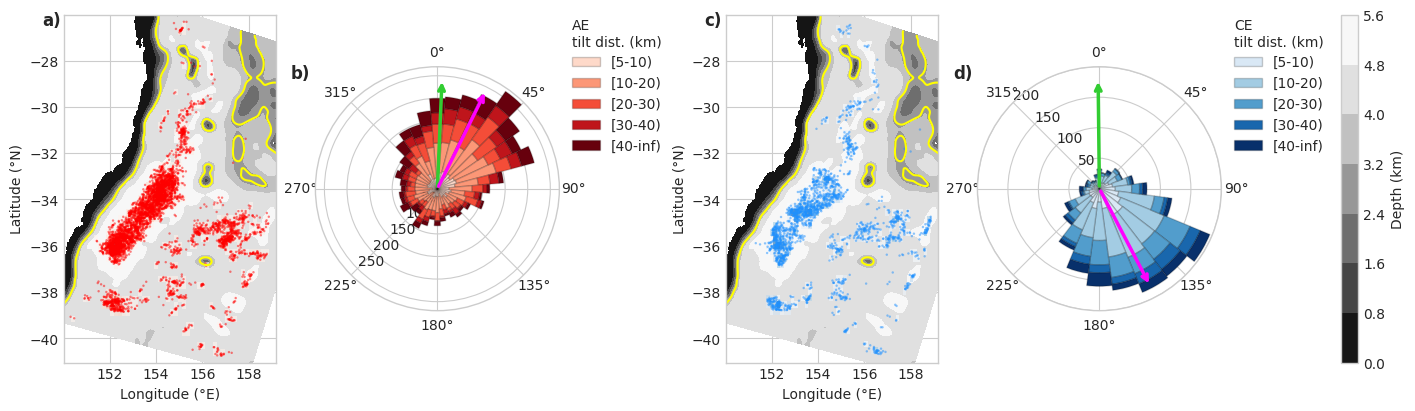

topo_dom_dtheta


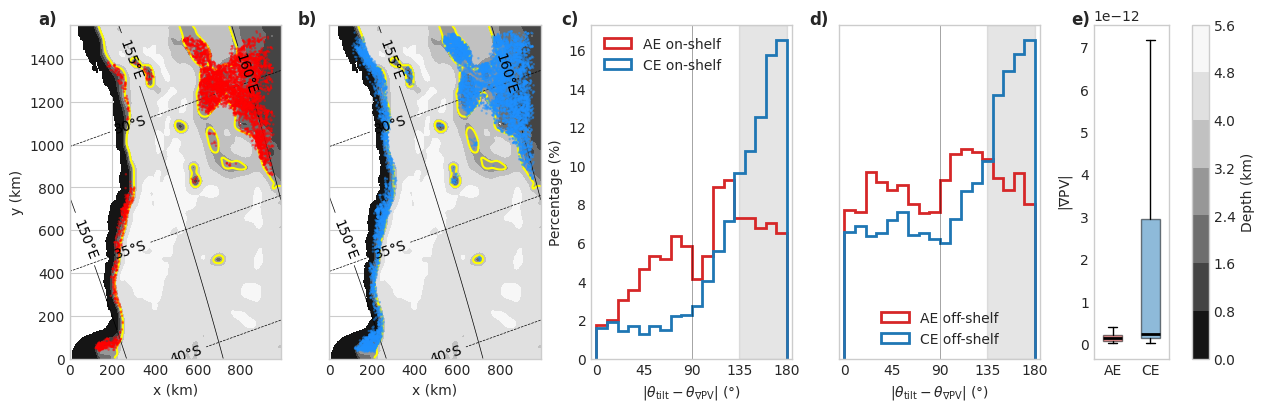

In [3]:
for name, figure in results["figures"].items():
    print(name)
    display(figure)

In [4]:
display(Markdown((results["output_dir"] / "report.md").read_text()))
display(results["inventory"])

# PV dominance results

Surface-fit environmental PV. Categories use raw component magnitudes: planetary ≥ 2× topographic; topographic ≥ 2× planetary; otherwise mixed. Invalid, negative or zero/zero magnitudes are unclassified. No smoothing in the classification. Percentages use classified days within each polarity.

Target populations: deep planetary = planetary dominated and h ≥3000 m; shallow topographic = topographic dominated and h ≤3000 m. Here h is the Gaussian-footprint-mean water depth used in the PV calculation, not profile depth. Other depth ranges are excluded from these targeted comparisons, never relabelled mixed. Missing/nonpositive water depths cannot enter a targeted population. Figures 7–9 retain all depths.

Direction analyses require tilt ≥5 km, finite tilt/PV bearings and positive finite total PV magnitude. Figures 7–9 do not require a valid tilt. Figure 7 uses a positive finite total PV vector; Figure 8 requires a finite log ratio/position. Figure 9 histograms require finite log ratios, while category bars use all classified days.

All-depth dominance inventory (before depth selection):

- AE planetary: 5,743 days / 590 eddies (8.54%); directional sample 4,454 days.
- AE mixed: 20,863 days / 1,087 eddies (31.02%); directional sample 15,304 days.
- AE topographic: 40,642 days / 1,407 eddies (60.44%); directional sample 29,293 days.
- CE planetary: 2,503 days / 461 eddies (3.80%); directional sample 1,875 days.
- CE mixed: 13,801 days / 1,002 eddies (20.98%); directional sample 9,984 days.
- CE topographic: 49,486 days / 1,576 eddies (75.22%); directional sample 36,102 days.

Targeted directional results (equal day weight; geographic bearings):

- AE deep_planetary: 4,449 days / 510 eddies; mean tilt bearing 26.3° (R=0.289); mean PV bearing 2.4°; aligned within 45°: 37.76%; opposed within 45°: 15.35%.
- AE shallow_topographic: 5,574 days / 346 eddies; mean tilt bearing 29.3° (R=0.288); mean PV bearing 289.7°; aligned within 45°: 22.19%; opposed within 45°: 26.25%.
- CE deep_planetary: 1,874 days / 397 eddies; mean tilt bearing 152.4° (R=0.509); mean PV bearing 359.3°; aligned within 45°: 8.64%; opposed within 45°: 48.56%.
- CE shallow_topographic: 8,855 days / 615 eddies; mean tilt bearing 201.4° (R=0.041); mean PV bearing 278.3°; aligned within 45°: 14.82%; opposed within 45°: 47.60%.

Depth selection audit (counts overlap in eddies across groups):

- AE planetary, depth eligible: 5,736 days / 583 eddies; 4,449 days also satisfy directional QC.
- AE planetary, planetary but shallower than threshold: 7 days / 7 eddies; 5 days also satisfy directional QC.
- AE topographic, depth eligible: 8,587 days / 397 eddies; 5,574 days also satisfy directional QC.
- AE topographic, topographic but deeper than threshold: 32,055 days / 1,276 eddies; 23,719 days also satisfy directional QC.
- CE planetary, depth eligible: 2,502 days / 460 eddies; 1,874 days also satisfy directional QC.
- CE planetary, planetary but shallower than threshold: 1 days / 1 eddies; 1 days also satisfy directional QC.
- CE topographic, depth eligible: 12,578 days / 711 eddies; 8,855 days also satisfy directional QC.
- CE topographic, topographic but deeper than threshold: 36,908 days / 1,411 eddies; 27,247 days also satisfy directional QC.

Figure notes:
- 7: original orange/purple regional rose layout. Geographic bearings are rotated into model-grid coordinates for display; shared census region boundaries. Offshore roses retain the original peak-normalisation, so their lengths do not compare regional sample sizes.
- 8: spatial mean of each day’s natural-log topographic/planetary magnitude ratio. Contours describe spatial bin means, not classifications of every day in the bin. Colours saturate at the original limits; counts and numerical tables retain all values.
- 9: original three-panel distribution/category/magnitude layout; axes expand to include the unsmoothed distribution instead of hiding tails. Zero-component ratios are not logged.
- 10: deep planetary-dominated days only, with the water-depth and directional criteria above. Original map/rose layout. Radial limits expand only where necessary to avoid clipping counts. Green/magenta arrows are circular mean PV/tilt directions.
- 12: shallow topographic-dominated days only, with the water-depth and directional criteria above. Original map/mismatch/boxplot layout. On/off-shelf remains a geographic longitude split at 154.75°E; equality is off-shelf. The 3000 m isobath marks the common depth threshold; selection uses footprint-mean h rather than the contour at the centre position.

These are descriptive associations. Repeated days are not independent eddies; no significance test or causal claim is implied. Per-regime eddy counts overlap across days and must not be summed as distinct eddies. The tables report counts and estimands explicitly.

CSV tables: regime_counts, figure_samples (exact populations/exclusions), map_bins (spatial means/support), depth_selection_counts (retained/excluded days and eddies), direction_summary (explicit all-depth or target population, and longitude groups), gradient_summary, sample_audit. PV gradients: m⁻² s⁻¹; distances: km; direction differences: degrees. See manifest.json for configurations, source/product identity and code hashes.


,Cyc,regime,eddy_days,eddies,classified_days,pct_classified,directional_days,directional_eddies,finite_log_ratio_days
0,AE,planetary,5743,590,67248,8.540031,4454,515,5743
1,AE,mixed,20863,1087,67248,31.023971,15304,969,20863
2,AE,topographic,40642,1407,67248,60.435998,29293,1331,40642
3,AE,unclassified,0,0,67248,NaN,0,0,0
4,CE,planetary,2503,461,65790,3.804530,1875,398,2503
5,CE,mixed,13801,1002,65790,20.977352,9984,925,13801
6,CE,topographic,49486,1576,65790,75.218118,36102,1536,49486
7,CE,unclassified,0,0,65790,NaN,0,0,0
